**Course outline:** Unit 01 · Notebook 01 · Python

# From data to a public health decision

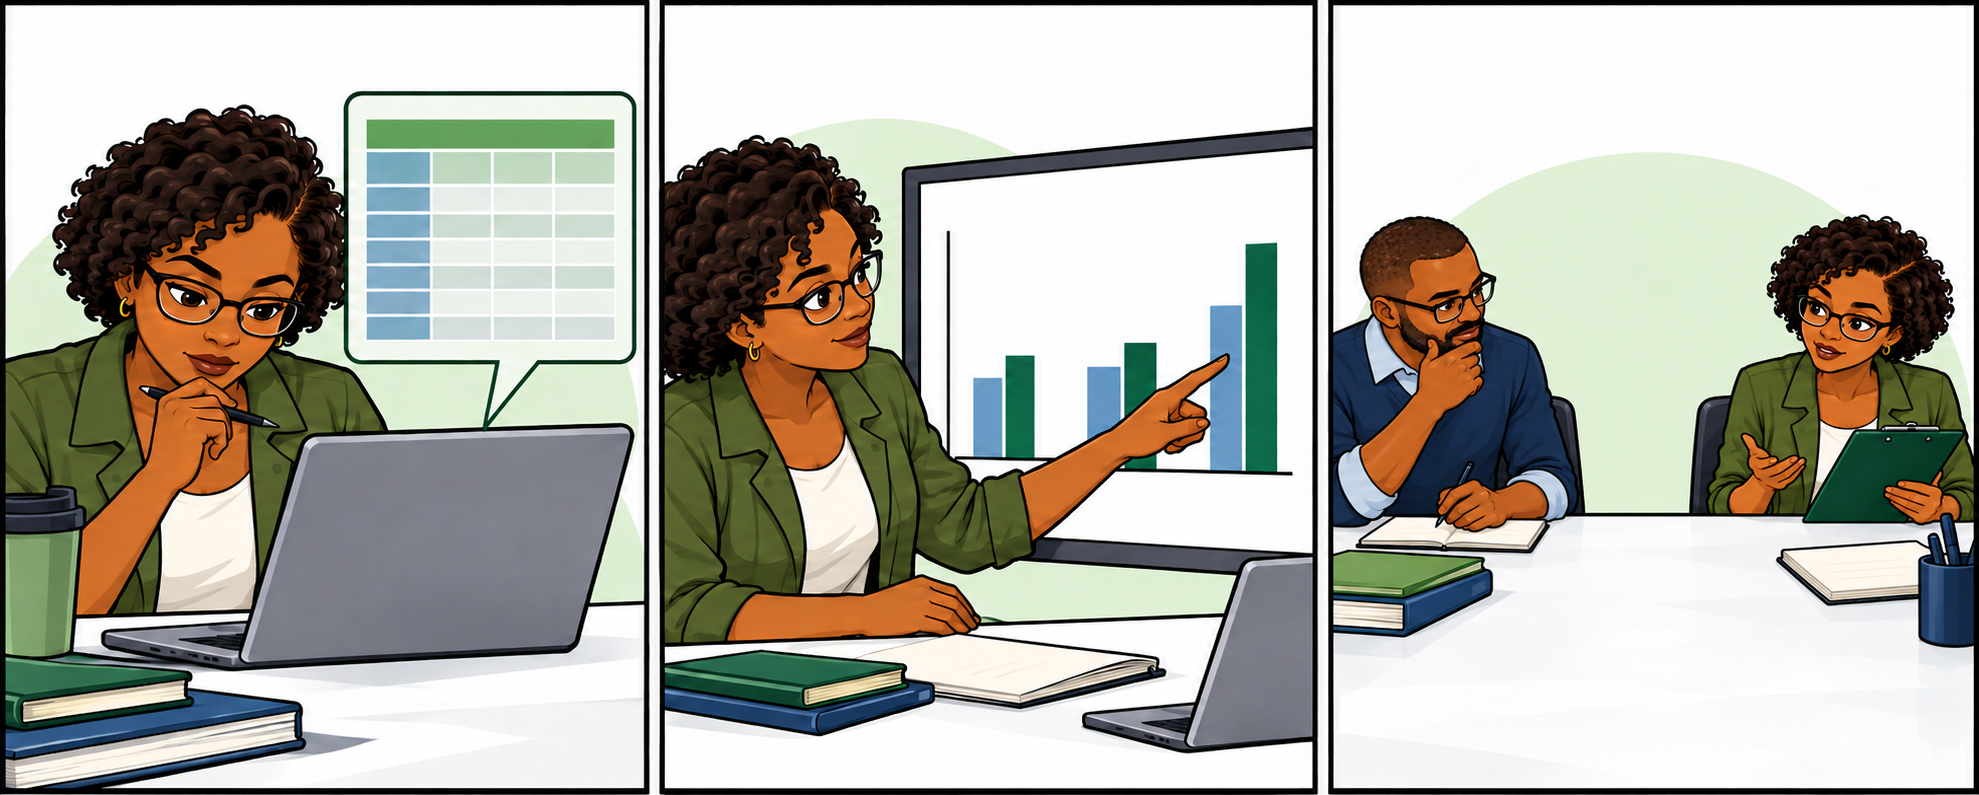

*Laila has more reports than time. She needs to find the clearest signal, then check it before drawing a conclusion.*

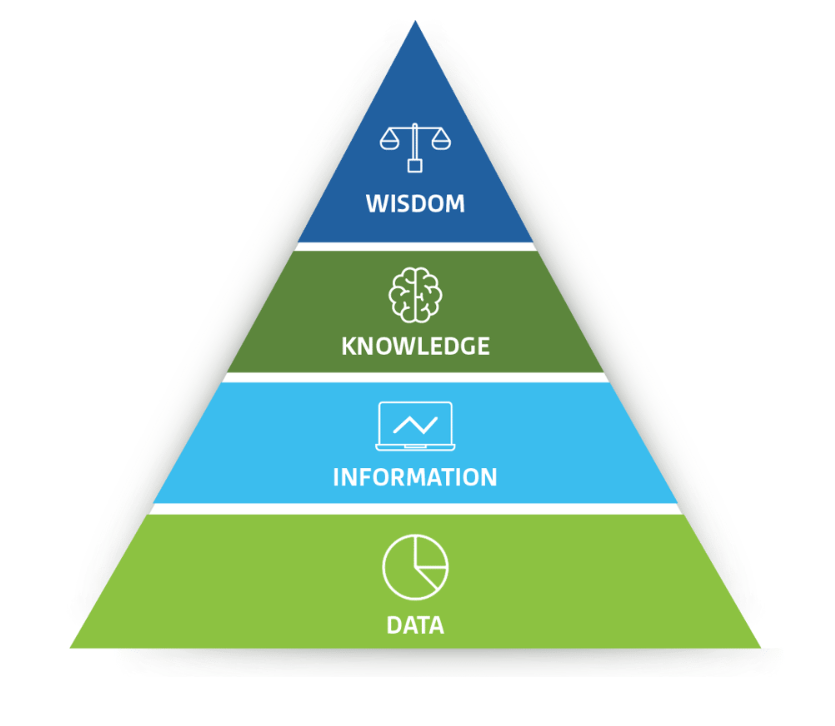

*You will turn raw reported counts (data) into a district comparison (information), interpret the change (knowledge), and select a cautious action (wisdom).*

**Learning objective:** **Select** a public health action using a supplied surveillance summary.

Laila's problem is **data overload**: locating, cleaning, and transforming reports into usable information takes time. Information is data organized with context; knowledge is an interpreted pattern; wisdom is a decision and action informed by that knowledge. You will follow that sequence with her reported counts.

## Scenario and task

Laila receives a small table of **synthetic weekly reported case counts**. The reports have not yet been verified. Run the setup cell to see the table. In the exercise cell:

1. Calculate each district's change: current week minus previous week.
2. Set `priority_district` to the district with the largest increase and `increase` to that numeric change.
3. Set `recommended_step` to one of the two strings below. Choose the first public health step supported by the table:
   - `"verify_reports_and_investigate"`: verify the reports and investigate the signal.
   - `"declare_confirmed_outbreak"`: declare a confirmed outbreak from these counts alone.

Then run the exercise cell and select **Submit** in the following cell for feedback. Running the computation does not record an attempt. The **Learning** panel records your submissions, offers hints, and recommends the next activity. Afterward, record a reflection explaining what the counts do and do not establish. The reflection is unscored.


In [ ]:
reports = [{'district': 'Kambia', 'week': 'previous', 'reported_cases': 2}, {'district': 'Kambia', 'week': 'current', 'reported_cases': 7}, {'district': 'Port Loko', 'week': 'previous', 'reported_cases': 3}, {'district': 'Port Loko', 'week': 'current', 'reported_cases': 4}, {'district': 'Bombali', 'week': 'previous', 'reported_cases': 4}, {'district': 'Bombali', 'week': 'current', 'reported_cases': 3}]
for row in reports:
    print(row)


In [ ]:
# Use reports to calculate the weekly change for each district.
# Replace the None values. You may add helper variables above them.
priority_district = None
increase = None
recommended_step = None


In [ ]:
# Run once to display Submit. Running this cell does not submit an attempt.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from IPython.display import display, clear_output
from comm import create_comm
from html import escape

def _show_course_submission():
    prepare = ''
    fields = ('priority_district', 'increase', 'recommended_step')
    controls_for_task = dict(globals().get("controls", {}))
    submit = widgets.Button(description="Submit", button_style="info", disabled=True)
    feedback = widgets.HTML(value="Connecting to your learning record...")
    artifact_output = widgets.Output(layout=widgets.Layout(width="100%"))
    channel = create_comm(target_name="al.submit", data={"cell": '2'})
    def status(text):
        feedback.value = '<div role="status" aria-live="polite">' + text + '</div>'
    def receive(message):
        data = message["content"]["data"]
        if data.get("ready"):
            status("When your answer is ready, select Submit for feedback.")
        elif data.get("outcome") == "Incomplete":
            status("<b>Not complete yet.</b> Answer every part, then submit again. This attempt was recorded.")
        elif data.get("outcome") == "Correct":
            status("<b>Correct.</b> Your submitted answer follows the stated data and rules. This attempt was recorded.")
        elif data.get("outcome") == "Incorrect":
            status("<b>Not yet correct.</b> Compare your submitted answer with the displayed data and rules. Revise and submit again. This attempt was recorded.")
        else:
            status(escape(data.get("error", "Could not record this attempt. Please submit again.")))
        for control in controls_for_task.values():
            control.disabled = False
        submit.disabled = False
    channel.on_msg(receive)
    def send(_):
        if submit.disabled:
            return
        submit.disabled = True
        for control in controls_for_task.values():
            control.disabled = True
        status("Checking and recording your submitted answer...")
        try:
            with artifact_output:
                clear_output(wait=True)
                exec(prepare, globals())
                if fields:
                    rows = ''.join('<tr><th style="text-align:left">' + escape(name) + '</th><td>' +
                                   escape(str(globals().get(name))) + '</td></tr>' for name in fields)
                    display(widgets.HTML('<b>Submitted answer</b><table>' + rows + '</table>'))
            channel.send({"submit": True})
        except Exception as error:
            status("Could not prepare your answer: " + escape(str(error)) + ". Run the required cells and try again. No attempt was submitted.")
            for control in controls_for_task.values():
                control.disabled = False
            submit.disabled = False
    def edited(_):
        if not submit.disabled:
            status("Changes not submitted. Select Submit for feedback.")
    for control in controls_for_task.values():
        control.observe(edited, names="value")
    submit.on_click(send)
    display(submit, artifact_output, feedback)

_show_course_submission()


## Your reflection

Run the next cell to enter your reflection. Select **Record** to save it in this browser. Your response is unscored.

In [ ]:
# Run this cell to write and record your reflections.
try:
    import ipywidgets as widgets
except ImportError:
    import piplite
    await piplite.install("ipywidgets==8.1.7")
    import ipywidgets as widgets
from html import escape
from IPython.display import display
from comm import create_comm

def _reflection_section(section, questions):
    prompts = [question["prompt"] for question in questions]
    fields = []
    for number, prompt in enumerate(prompts, 1):
        field = widgets.Textarea(placeholder="Write your reflection here", rows=5,
                                 layout=widgets.Layout(width="100%"))
        fields.append(field)
        display(widgets.VBox([
            widgets.HTML(value=f"<strong>{number}. {escape(prompt)}</strong>"), field
        ], layout=widgets.Layout(width="100%", padding="0.5rem", margin="0 0 0.5rem 0")))
    button = widgets.Button(description="Record", button_style="info", disabled=True)
    status = widgets.HTML(value="Connecting to your browser learner record...")
    status.add_class("course-reflection-status")
    channel = create_comm(target_name="al.reflections", data={"section": section})
    def receive(message):
        data = message["content"]["data"]
        if "entries" in data:
            entries = data["entries"]
            restored = 0
            earlier = 0
            for question, field in zip(questions, fields):
                saved = next((entry for entry in reversed(entries) if
                    (entry.get("id") == question["id"] and entry.get("version") == question["version"]) or
                    (question["version"] == 1 and not entry.get("id") and entry["prompt"] in question["legacyPrompts"])), None)
                field.value = saved["answer"] if saved else ""
                restored += saved is not None
                earlier += any(entry.get("id") == question["id"] and entry.get("version") != question["version"] for entry in entries)
            status.value = "Recorded reflections restored." if restored else "Select Record to save in this browser."
            if earlier or any(entry.get("history") for entry in entries) or len(entries) > restored:
                status.value += " Earlier responses remain in My learning record and Download reflections. Review them before answering revised questions."
        elif data.get("saved"):
            status.value = "Recorded in this browser. Your reflections are unscored."
        else:
            status.value = escape(data.get("error", "Could not record. Please try again."))
        button.disabled = False
    channel.on_msg(receive)
    def record(_):
        button.disabled = True
        status.value = "Recording..."
        channel.send({"entries": [{**question, "answer": field.value}
                                  for question, field in zip(questions, fields)]})
    def edited(_):
        status.value = "Changes not recorded. Select Record to save."
    for field in fields:
        field.observe(edited, names="value")
    button.on_click(record)
    display(button, status)

_reflection_section('exercise:u01-n01', [{'id': 'q-e0fa857943f2', 'version': 1, 'prompt': 'Why is the chosen action justified, and what remains uncertain?', 'legacyPrompts': ['Why is the chosen action justified, and what remains uncertain?']}])


## Continue the case

The counts are synthetic. Verify a signal before treating it as an outbreak. Use
the **Learning** panel for your next activity or retry this decision after
checking the district changes.


## References

- UCSF-IGHS, *FETP JupyterBook*, Unit 1 informatics lesson; adapted with synthetic weekly reports.
- [Unit 1 course slides (local PDF)](../../readings/ucsf/assets/unit-1-version-2-slides.pdf).
